# Autism traits prediction: what is the model really using?

**Goal:** predict the column `ASD_traits` (yes / no) of a screening dataset for children with logistic regression, AdaBoost, SVM and Random Forest, and find out **what the models are actually using** to do it.

**Data:** *ASD risk-factor screening data* (Kaggle `uppulurimadhuri/dataset`): 1,985 children, 28 columns. It contains the answers to ten screening questions (`A1` to `A10`), the Q-Chat-10 score, a social-responsiveness score, a childhood-autism rating, demographics, family history and several associated conditions.

**An important note:** this is a *screening* dataset, not a diagnosis. Nothing in this notebook is medical advice or a clinical tool; it is an exercise in evaluating a model honestly.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text

sns.set_theme(style="whitegrid")
SEED = 42

## 1. The data

In [2]:
raw = pd.read_csv("data/data_csv.csv")
CASE = "CASE_NO_PATIENT'S"
print("Rows, columns:", raw.shape)
print("Missing values per column (only those with any):", {k: int(v) for k, v in raw.isna().sum().items() if v})
raw["y"] = (raw["ASD_traits"].astype(str).str.strip().str.lower() == "yes").astype(int)
print(f"Share with ASD_traits = yes: {raw['y'].mean():.1%}  -> always answering 'yes' would be {max(raw['y'].mean(), 1 - raw['y'].mean()):.1%} accurate")
raw.head(3)

Rows, columns: (1985, 28)
Missing values per column (only those with any): {'Social_Responsiveness_Scale': 9, 'Qchat_10_Score': 39, 'Depression': 1, 'Social/Behavioural Issues': 14}
Share with ASD_traits = yes: 54.1%  -> always answering 'yes' would be 54.1% accurate


,CASE_NO_PATIENT'S,A1,A2,A3,A4,A5,A6,A7,A8,A9,...,Social/Behavioural Issues,Childhood Autism Rating Scale,Anxiety_disorder,Sex,Ethnicity,Jaundice,Family_mem_with_ASD,Who_completed_the_test,ASD_traits,y
0,1,0,0,0,0,0,0,1,1,0,...,Yes,1,Yes,F,middle eastern,Yes,No,Family Member,No,0
1,2,1,1,0,0,0,1,1,0,0,...,Yes,2,Yes,M,White European,Yes,No,Family Member,Yes,1
2,3,1,0,0,0,0,0,1,1,0,...,Yes,4,Yes,M,Middle Eastern,Yes,No,Family Member,Yes,1


## 2. Problems in the data

A model is only as good as its data. Three things stand out before any modelling.

**a) One third of the rows are repeated.** If a repeated child lands in both the training and the test set, the score is inflated.

In [3]:
df = raw.copy()
for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].astype(str).str.strip()
feature_cols = [c for c in df.columns if c not in (CASE, "ASD_traits", "y")]
df["group"] = pd.factorize(pd.util.hash_pandas_object(df[feature_cols].astype(str), index=False))[0]
print(f"{len(df)} rows, but only {df.group.nunique()} different children: {len(df) - df.group.nunique()} rows ({1 - df.group.nunique() / len(df):.0%}) are exact repeats.")
print("Repeated rows with conflicting labels:", int((df.groupby('group').y.nunique() > 1).sum()))

1985 rows, but only 1329 different children: 656 rows (33%) are exact repeats.
Repeated rows with conflicting labels: 0


**b) The spelling of a category carries information.** The file looks assembled from several sources with different spelling habits. The rate of `ASD_traits = yes` changes dramatically with *how a word is written*:

,rate,rows
Ethnicity,,
south asian,3%,206
asian,15%,213
Middle Eastern,21%,362
middle eastern,51%,41
South Asian,61%,49
Hispanic,75%,40
Asian,80%,392
Black,80%,45
White European,85%,549


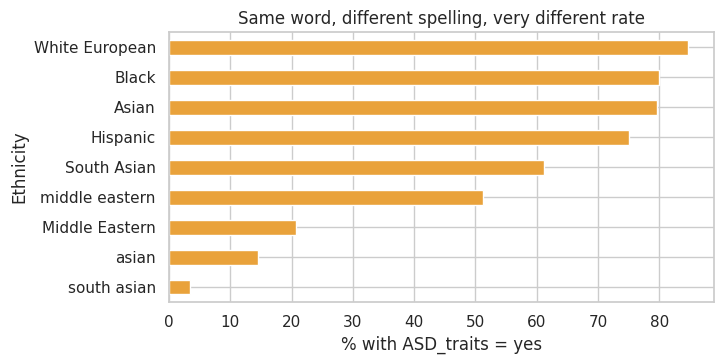

In [4]:
eth = df.groupby("Ethnicity").y.agg(rate="mean", rows="count").query("rows >= 40").sort_values("rate")
display(eth.round(2).style.format({"rate": "{:.0%}"}))
fig, ax = plt.subplots(figsize=(7.4, 3.8)); (eth["rate"] * 100).plot.barh(ax=ax, color="#e9a23b")
ax.set_xlabel("% with ASD_traits = yes"); ax.set_title("Same word, different spelling, very different rate"); plt.tight_layout(); plt.show()

`Asian` (80%) against `asian` (15%), `South Asian` (61%) against `south asian` (3%): these are not different populations, they are different **sources**. A model fed with this column, as the first version of this project did (a label encoder over the raw text, so every spelling was its own category), learns where a row came from.

**c) Seven columns are almost the same column.** The associated conditions (speech delay, learning disorder, genetic disorders, depression, global developmental delay, social/behavioural issues, anxiety) nearly always take the same value:

In [5]:
flags = ["Speech Delay/Language Disorder", "Learning disorder", "Genetic_Disorders", "Depression",
         "Global developmental delay/intellectual disability", "Social/Behavioural Issues", "Anxiety_disorder"]
F = pd.concat([(df[c].str.lower() == "yes").astype(int) for c in flags], axis=1); F.columns = flags
print(f"Rows where all 7 flags agree: {(F.nunique(axis=1) == 1).mean():.0%}")
print(f"Lowest agreement between any two flags: {min((F[a] == F[b]).mean() for i, a in enumerate(flags) for b in flags[i + 1:]):.1%}")

Rows where all 7 flags agree: 96%
Lowest agreement between any two flags: 96.9%


**d) Even the row order carries information.** The case number is just a counter, yet the share of `yes` changes along the file, which again points to blocks of rows from different sources:

In [6]:
order = pd.qcut(raw[CASE], 5, labels=["first fifth", "2nd", "3rd", "4th", "last fifth"])
display(df.assign(position=order).groupby("position").y.mean().to_frame("share with ASD_traits = yes").round(2).T)

position,first fifth,2nd,3rd,4th,last fifth
share with ASD_traits = yes,0.64,0.75,0.58,0.35,0.38


## 3. The label is the screening result

The ten questions `A1` to `A10` are answered 0 or 1. What does `ASD_traits` look like as a function of how many were answered 1?

items_sum,0,1,2,3,4,5,6,7,8,9,10
rate,0.41,0.14,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
children,717.00,356.00,88.0,96.0,110.0,120.0,96.0,135.0,97.0,95.0,75.0


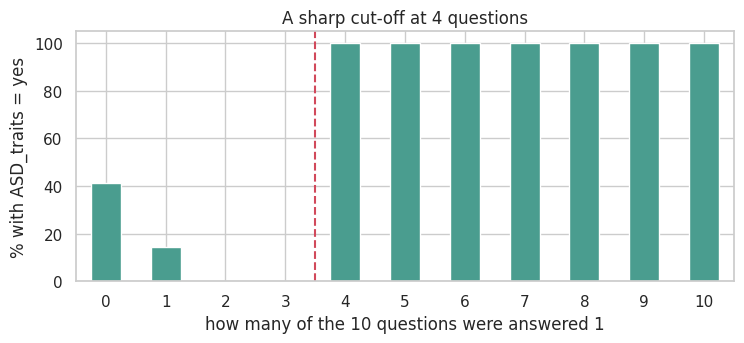

For children with 2 or more positive answers (912 of 1985), the label equals 'sum >= 4' in 100% of cases.


In [7]:
ITEMS = ["A1", "A2", "A3", "A4", "A5", "A6", "A7", "A8", "A9", "A10_Autism_Spectrum_Quotient"]
df["items_sum"] = df[ITEMS].astype(int).sum(axis=1)
by_sum = df.groupby("items_sum").y.agg(rate="mean", children="count")
display(by_sum.T.round(2))
fig, ax = plt.subplots(figsize=(7.6, 3.6)); (by_sum["rate"] * 100).plot.bar(ax=ax, color="#4a9d8f", rot=0)
ax.axvline(3.5, color="#d1495b", ls="--"); ax.set_ylabel("% with ASD_traits = yes"); ax.set_xlabel("how many of the 10 questions were answered 1")
ax.set_title("A sharp cut-off at 4 questions"); plt.tight_layout(); plt.show()
sure = df[df.items_sum.between(2, 10)]
print(f"For children with 2 or more positive answers ({len(sure)} of {len(df)}), the label equals 'sum >= 4' in {((sure.items_sum >= 4).astype(int) == sure.y).mean():.0%} of cases.")

With 2 to 10 positive answers the label is **exactly** "4 or more": that is the standard cut-off of this kind of screening questionnaire. In other words, `ASD_traits` is, for most children, **the result of the questionnaire itself**. Using the questions to "predict" it is predicting a rule from its own inputs.

## 4. What can each family of inputs predict?

Four input sets, the four models of the first version, and an evaluation that fixes its two problems: **5-fold cross-validation grouped by child** (a repeated row never sits on both sides) and **all the data used for testing in turn**, instead of one 5% split.

Accuracy of always answering the majority class: 0.541

Accuracy (5-fold, grouped by child)


model,AdaBoost,Logistic regression,Random forest,SVM
inputs,,,,
A. the 10 screening questions only,0.758,0.764,0.806,0.814
B. everything (as in the first version),0.993,0.952,1.000,0.993
"C. the three scores only (Q-Chat, SRS, CARS)",0.719,0.729,0.791,0.743
"D. background only (no questions, no scores)",0.816,0.820,0.813,0.833


ROC-AUC


model,AdaBoost,Logistic regression,Random forest,SVM
inputs,,,,
A. the 10 screening questions only,0.836,0.836,0.893,0.875
B. everything (as in the first version),1.000,0.993,1.000,1.000
"C. the three scores only (Q-Chat, SRS, CARS)",0.870,0.764,0.942,0.805
"D. background only (no questions, no scores)",0.833,0.834,0.888,0.886


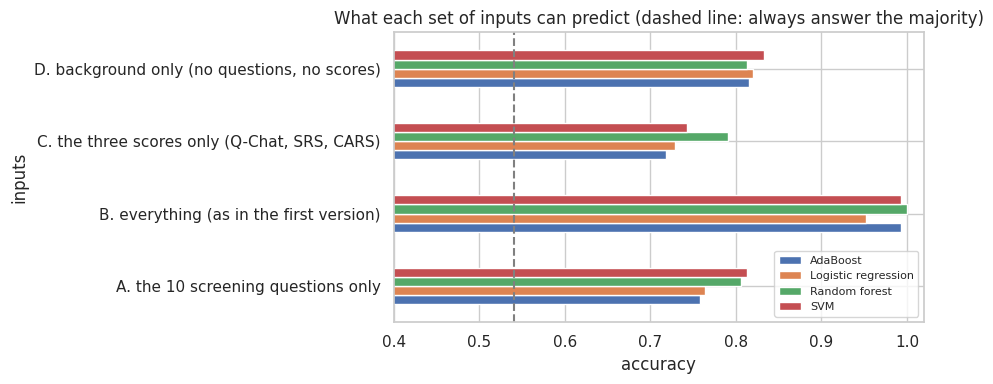

In [8]:
df["Age_Years"] = df["Age_Years"].astype(float)
SCORES = ["Qchat_10_Score", "Social_Responsiveness_Scale", "Childhood Autism Rating Scale"]
BG_CAT = ["Sex", "Ethnicity", "Jaundice", "Family_mem_with_ASD", "Who_completed_the_test"] + flags
clean = df.copy()
for c in clean.select_dtypes(exclude="number").columns:
    clean[c] = clean[c].str.lower()                                   # one spelling per category
for c in ITEMS + SCORES:
    clean[c] = pd.to_numeric(clean[c], errors="coerce")

def pipeline(num, cat, model):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat)])
    return Pipeline([("pre", pre), ("model", model)])

MODELS = {
    "Logistic regression": lambda: LogisticRegression(max_iter=2000),
    "AdaBoost":            lambda: AdaBoostClassifier(n_estimators=200, random_state=SEED),
    "SVM":                 lambda: SVC(),
    "Random forest":       lambda: RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}
INPUTS = {
    "A. the 10 screening questions only":                (ITEMS, []),
    "B. everything (as in the first version)":           (ITEMS + SCORES + ["Age_Years"], BG_CAT),
    "C. the three scores only (Q-Chat, SRS, CARS)":      (SCORES, []),
    "D. background only (no questions, no scores)":      (["Age_Years"], BG_CAT),
}
gkf = GroupKFold(n_splits=5)
rows = []
for iname, (num, cat) in INPUTS.items():
    for mname, make in MODELS.items():
        r = cross_validate(pipeline(num, cat, make()), clean[num + cat], clean.y, groups=clean.group, cv=gkf, scoring=["accuracy", "roc_auc"])
        rows.append({"inputs": iname, "model": mname, "accuracy": r["test_accuracy"].mean(), "ROC-AUC": r["test_roc_auc"].mean()})
res = pd.DataFrame(rows)
acc = res.pivot(index="inputs", columns="model", values="accuracy"); auc = res.pivot(index="inputs", columns="model", values="ROC-AUC")
print(f"Accuracy of always answering the majority class: {max(clean.y.mean(), 1 - clean.y.mean()):.3f}\n")
print("Accuracy (5-fold, grouped by child)"); display(acc.round(3))
print("ROC-AUC"); display(auc.round(3))
fig, ax = plt.subplots(figsize=(9.5, 4)); acc.plot.barh(ax=ax); ax.axvline(max(clean.y.mean(), 1 - clean.y.mean()), color="grey", ls="--")
ax.set_xlim(0.4, 1.02); ax.set_xlabel("accuracy"); ax.set_title("What each set of inputs can predict (dashed line: always answer the majority)"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

- **B (everything):** the random forest reaches **1.000** and AdaBoost and SVM **0.993**. That is not insight: the inputs include the questionnaire that *defines* the label (section 3).
- **A (only the 10 questions):** 0.76 to 0.81, lower because of the children with 0 or 1 positive answers, whose label depends on other things.
- **C (only the three scores):** 0.72 to 0.79.
- **D (only background):** 0.81 to 0.83, far above the 0.54 majority line, **with no questionnaire and no score at all**. The next section looks at why.

## 5. Where does the background-only result come from?

In [9]:
BG_NUM = ["Age_Years"]
variants = {
    "all background":                          (BG_NUM, BG_CAT),
    "without ethnicity":                       (BG_NUM, [c for c in BG_CAT if c != "Ethnicity"]),
    "without the 7 near-identical flags":      (BG_NUM, [c for c in BG_CAT if c not in flags]),
    "without ethnicity and without the flags": (BG_NUM, [c for c in BG_CAT if c != "Ethnicity" and c not in flags]),
}
rows = []
for vname, (num, cat) in variants.items():
    for mname in ("Logistic regression", "Random forest"):
        r = cross_validate(pipeline(num, cat, MODELS[mname]()), clean[num + cat], clean.y, groups=clean.group, cv=gkf, scoring=["accuracy", "roc_auc"])
        rows.append({"background variables": vname, "model": mname, "accuracy": r["test_accuracy"].mean(), "ROC-AUC": r["test_roc_auc"].mean()})
abl = pd.DataFrame(rows).pivot(index="background variables", columns="model", values=["accuracy", "ROC-AUC"]).round(3)
display(abl.loc[list(variants)])

accuracy                \
model                                   Logistic regression Random forest   
background variables                                                        
all background                                        0.820         0.813   
without ethnicity                                     0.638         0.635   
without the 7 near-identical flags                    0.814         0.781   
without ethnicity and without the flags               0.654         0.617   

                                                    ROC-AUC                
model                                   Logistic regression Random forest  
background variables                                                       
all background                                        0.834         0.888  
without ethnicity                                     0.729         0.679  
without the 7 near-identical flags                    0.840         0.840  
without ethnicity and without the flags               0.717         0.640

Removing the **ethnicity** column (the one whose spelling identifies the source) drops the accuracy from about 0.82 to 0.64, while removing the near-identical flags changes it much less (0.81 for logistic regression, 0.78 for the random forest). Without both it is 0.62 to 0.65: still above the 0.54 majority line, so some genuine association remains (sex and family history, for example), but **most of the apparent signal in "background" comes from how the file was put together**, not from clinical information.

## 6. What do the repeated rows cost?

In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for iname, (num, cat) in INPUTS.items():
    X = clean[num + cat]
    rnd = cross_validate(pipeline(num, cat, MODELS["Random forest"]()), X, clean.y, cv=skf, scoring="accuracy")["test_score"].mean()
    grp = cross_validate(pipeline(num, cat, MODELS["Random forest"]()), X, clean.y, groups=clean.group, cv=gkf, scoring="accuracy")["test_score"].mean()
    rows.append({"inputs (random forest)": iname, "random folds": rnd, "folds grouped by child": grp, "inflation": rnd - grp})
display(pd.DataFrame(rows).set_index("inputs (random forest)").round(3))

,random folds,folds grouped by child,inflation
inputs (random forest),,,
A. the 10 screening questions only,0.810,0.806,0.004
B. everything (as in the first version),1.000,1.000,0.000
"C. the three scores only (Q-Chat, SRS, CARS)",0.872,0.791,0.080
"D. background only (no questions, no scores)",0.811,0.813,-0.002


Repeated rows matter for the **scores-only** model: 0.872 with random folds against 0.791 when a child never appears on both sides, so 8 points of the score came from memorised rows. For the other input sets there is no measurable difference, but grouping costs nothing and is the safe default.

## 7. What would a transparent model look like?

A shallow decision tree on everything shows what the data really says: it splits first on the questionnaire scores.

In [11]:
num_all = ITEMS + SCORES + ["Age_Years"]
X = pd.concat([clean[num_all].fillna(-1), pd.get_dummies(clean[BG_CAT + []], dtype=int)], axis=1)
tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X, clean.y)
print(f"Depth-3 tree, accuracy on the data it was fitted on: {tree.score(X, clean.y):.3f}\n")
print(export_text(tree, feature_names=list(X.columns)))

Depth-3 tree, accuracy on the data it was fitted on: 0.910

|--- Qchat_10_Score <= 3.50
|   |--- Qchat_10_Score <= 1.50
|   |   |--- Sex_m <= 0.50
|   |   |   |--- class: 0
|   |   |--- Sex_m >  0.50
|   |   |   |--- class: 1
|   |--- Qchat_10_Score >  1.50
|   |   |--- Jaundice_yes <= 0.50
|   |   |   |--- class: 0
|   |   |--- Jaundice_yes >  0.50
|   |   |   |--- class: 0
|--- Qchat_10_Score >  3.50
|   |--- Speech Delay/Language Disorder_no <= 0.50
|   |   |--- A7 <= 0.50
|   |   |   |--- class: 1
|   |   |--- A7 >  0.50
|   |   |   |--- class: 1
|   |--- Speech Delay/Language Disorder_no >  0.50
|   |   |--- Ethnicity_white european <= 0.50
|   |   |   |--- class: 0
|   |   |--- Ethnicity_white european >  0.50
|   |   |   |--- class: 1



## 8. Conclusions

- **The 100% is not a finding.** With the inputs of the first version the random forest scores 1.000, but `ASD_traits` is, for the 912 children with 2 or more positive answers, **exactly** the questionnaire's own cut-off ("4 or more"). The model reads the rule from its own inputs.
- **Without any questionnaire or score, the models still reach 0.81 to 0.83** (the majority line is 0.54), but most of that comes from the **spelling of the ethnicity column**, which identifies where a row came from: removing it drops the accuracy to 0.64.
- **The file was assembled from several sources:** one third of the rows are repeats, seven condition columns are nearly the same column, spelling variants have very different rates (`Asian` 80%, `asian` 15%), and even the row order is related to the label.
- **Repeated rows inflate scores:** 8 points for the scores-only model (0.872 against 0.791 when grouped by child).
- **So this dataset cannot support claims about predicting autism.** What the notebook does show is how to find out why a score is too good: check what defines the label, evaluate by group, remove the inputs that give the answer away, and look for traces of how the data was put together.

**Limitations**

- This is a screening dataset with unclear provenance, not a clinical study. Nothing here is medical advice.
- Removing inputs and grouping reduces the problems but cannot prove that every source artefact has been found.
- Ethnicity is analysed here only as a data-quality signal, never as a predictor to use.

**Next steps:** repeat the exercise on a documented public screening dataset with known provenance, evaluate by source (train on some sources, test on another) and report the result for children with 0 or 1 positive answers separately, since that is the only group where the label is not defined by the questionnaire.